# Lesson 7: Investigating the results of the iES runs

Now that the model iES run is finished, we will look into the progress of objective function (phi) with iteration, as well as the model performance (only KGE) at the best iteration. 

In [1]:
import pandas as pd
import pyemu
import sys
import shutil
import os
import numpy as np
from pathlib import Path
from datetime import datetime as dt
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from pytsproc import filters, series_metrics
plt.rcParams['font.size']=12
%matplotlib inline
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [2]:
kge_calc = pyemu.metrics._KGE

Let us define where the output directory of the iES experiment is, and also the path where the figures will be saved for this lesson. 

In [3]:
test_root = 'wrfpst' 
wkdir = Path('/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson3/host') # original host directory
outdir = Path('/glade/u/home/arezoo/wrf_hydro_training/output/pestpp/lesson4/plots')
if not os.path.exists(outdir):
    outdir.mkdir(parents = True)

## Read in the phi of ensemble 
We will read the phi values for all the iterations.

In [4]:
phi = pd.read_csv(wkdir / f'{test_root}.phi.actual.csv')

In [5]:
phi

,iteration,total_runs,mean,standard_deviation,min,max,0,1,2,3,...,18,19,20,21,22,23,24,25,26,base
0,0,0,519.9150,291.0090,46.1971,1015.440,363.684,400.1960,373.120,587.9580,...,847.0970,128.5670,754.4830,623.5360,46.1971,148.7770,642.9540,764.5990,982.278,524.0000
1,1,28,170.4440,164.5540,37.2277,860.282,189.233,136.0330,122.379,233.9790,...,154.3240,121.4190,175.5860,140.6800,76.5032,54.3995,49.3721,860.2820,166.350,59.0346
2,2,55,57.7567,26.5477,27.1946,134.586,31.534,37.9925,99.024,71.0793,...,42.4988,62.3631,29.8629,74.2701,31.0071,49.6085,48.8875,51.0836,134.586,78.9617


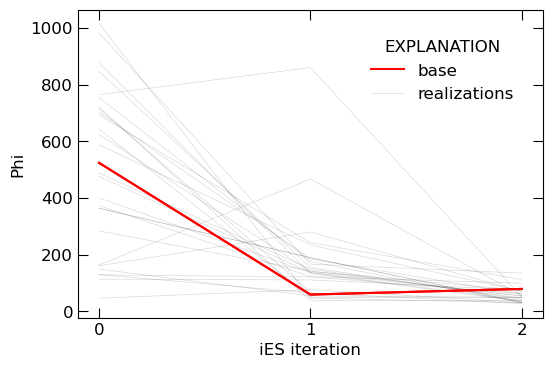

In [6]:
plt.figure(figsize=(6,4))
ax = phi['base'].plot(legend=False, lw=1.5, color='r', label='base')
phi.iloc[:,6:7].plot(legend=False,lw=0.5,color='k',alpha=0.15,label='realizations', ax = ax)
plt.legend(['base','realizations'])
phi.iloc[:,6:].plot(legend=False,lw=0.5,alpha=0.15,color='k', ax = ax)
phi['base'].plot(legend=False, lw=1.5, color='r', ax=ax)
plt.ylabel('Phi')
plt.xlabel('iES iteration')
plt.xticks(ticks=np.arange(3))
ax.axes.tick_params(length=7, direction='in', right=True, top=True)
plt.legend(['base','realizations'], title='EXPLANATION', frameon=False, bbox_to_anchor =(0.97, 0.95))


### Define what iteration is the best

This is so going forward we plot the information related to this iteration. 

In [9]:
best_iter=2
phivec = phi.loc[best_iter][5:].copy().dropna()

<Axes: >

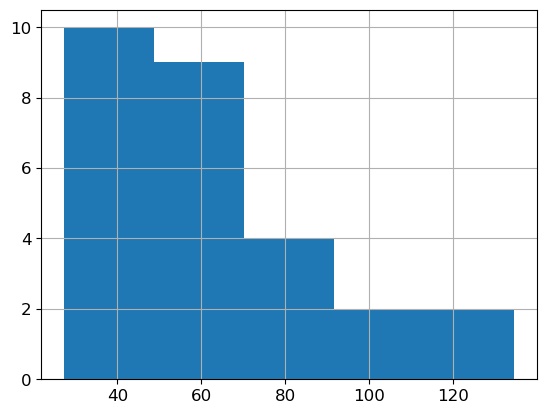

In [10]:
phivec.hist(bins=5)

### Rejection sampling 

We usually do not use all the ensemble members if there is a ensemble size is large, 
however, this training has only 30 members to start with, which a few were dropped at the rejection sampling step prior to the iES. 
We will drop any members with phi values higher than 500 going forward.

In [11]:
phi_too_high = 100

Number of reals before rejection sampling: 27
Number of reals after rejection sampling: 24


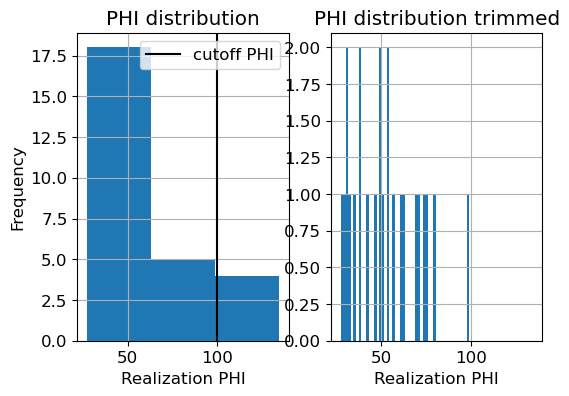

In [12]:
fig, ax = plt.subplots(1,2, figsize=(6,4))
phivec.hist(bins=3, ax=ax[0])
ax[0].axvline(phi_too_high, color='k', label='cutoff PHI')
ax[0].legend()
ax[0].set_ylabel('Frequency')
print('Number of reals before rejection sampling: {}'.format(len(phivec)))
phivec = phivec[phivec<phi_too_high]
print('Number of reals after rejection sampling: {}'.format(len(phivec)))
phivec.hist(bins=50, ax=ax[1])
ax[1].set_xlim(ax[0].get_xlim())
ax[0].set_xlabel('Realization PHI')
ax[1].set_xlabel('Realization PHI')
ax[0].set_title('PHI distribution')
ax[1].set_title('PHI distribution trimmed')

handles, labels = ax[0].get_legend_handles_labels()
ax[0].legend(handles, labels, loc='best')

In [13]:
reals_to_keep = phivec.index.values
reals_to_keep

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '13',
       '14', '15', '18', '19', '20', '21', '22', '23', '24', '25', 'base'],
      dtype=object)

## Read in the ensemble of model simulations 

In [14]:
if not os.path.exists(wkdir / f'{test_root}.{best_iter}.obs.csv'):
    with tarfile.open(wkdir / f'{test_root}.{best_iter}.obs.csv.tar') as ctar:
        ctar.extractall(wkdir)
obens = pd.read_csv(wkdir / f'{test_root}.{best_iter}.obs.csv', index_col=0, dtype={'real_name':str})

In [15]:
print(len(obens))
obens=obens.loc[reals_to_keep]
print(len(obens))

26
24


In [16]:
obens

,kge,obs_20180801_010000,obs_20180801_020000,obs_20180801_030000,obs_20180801_040000,obs_20180801_050000,obs_20180801_060000,obs_20180801_070000,obs_20180801_080000,obs_20180801_090000,...,obs_20180831_150000,obs_20180831_160000,obs_20180831_170000,obs_20180831_180000,obs_20180831_190000,obs_20180831_200000,obs_20180831_210000,obs_20180831_220000,obs_20180831_230000,obs_20180901_000000
real_name,,,,,,,,,,,,,,,,,,,,,
0,0.690163,103.9470,165.5760,856.4630,1117.2300,986.3490,821.2840,633.6230,484.4040,377.3270,...,7.93887,7.97671,8.19122,8.47509,9.03615,10.38090,11.55530,15.96360,19.03740,24.11140
1,0.554567,67.9933,74.7439,252.5000,557.5310,563.3860,495.7010,426.3940,354.3400,289.2830,...,3.15647,3.20086,3.41583,3.62240,4.13456,5.71426,6.59650,10.75800,14.14070,19.44570
2,0.545419,90.0368,104.5070,546.5520,899.6800,785.1330,673.9080,546.7210,430.5430,340.1260,...,12.53100,12.57790,12.57310,12.59260,12.83810,13.76690,14.42670,17.01570,18.90950,21.40710
3,0.543349,62.3918,66.8281,204.8210,470.9060,508.9910,454.8360,397.3330,336.8750,280.0110,...,11.12270,11.14150,11.29570,11.46830,11.93900,13.16520,14.10910,17.44950,19.94660,23.77590
4,0.418839,166.5480,499.5980,2044.9900,1949.7400,1626.8200,1153.6200,819.7470,612.4180,480.7990,...,7.04058,7.04008,7.05321,7.05350,7.07363,7.35159,7.51307,8.58706,9.04438,9.90533
5,0.457177,65.2635,62.0083,198.4480,481.9430,504.6820,442.5310,384.1110,325.0790,269.5110,...,3.14400,3.13324,3.13464,3.32066,3.43620,3.75486,3.83156,4.95990,5.44165,6.68515
6,0.750331,63.7016,62.0044,191.3530,463.1550,496.2800,439.5100,383.5600,326.0360,271.2450,...,6.01442,6.11815,6.46281,6.85134,7.82288,9.83142,11.51890,16.94900,22.17640,30.46780
7,0.669743,66.7897,72.7774,241.4180,541.5010,552.6950,486.3910,419.1000,349.3920,286.0380,...,6.57856,6.65944,6.89229,7.33319,8.24110,10.21810,11.88470,16.70280,21.58290,29.16380
8,0.525558,35.4199,32.4644,59.1148,114.5910,182.6040,205.6580,194.8440,175.8690,156.7400,...,13.82130,13.95510,14.08900,14.30050,14.80700,15.96620,17.13490,21.04040,24.16650,28.15660


The first entry of the observation is the kge values calculated through the post processing script. We display the KGE values which are for duration of the calibration period. 

In [17]:
kge = obens.kge

<Axes: >

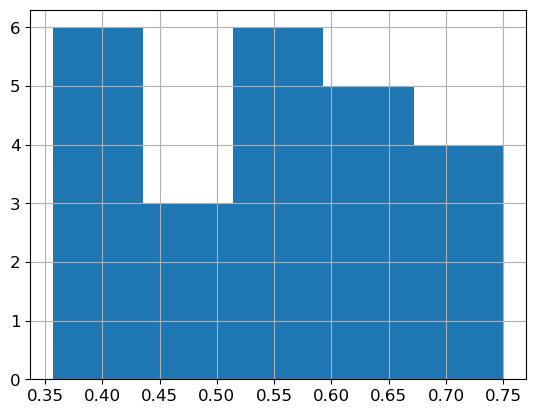

In [18]:
kge.hist(bins=5)

In [19]:
# Function for parsing the name of the observation 
def parsename(cn):
    '''
    parse the dates from the WRF_hydro obs names
    '''
    tmp = cn.replace('obs_','')
    return dt.strptime(tmp, '%Y%m%d_%H0000')

In [20]:
obens = obens[obens.columns[1:]]
obens = obens.T

datetime = [parsename(i) for i in obens.index]
obens.index = datetime

# Plot the streamflow ensemble 

First let's read the observation. We define a simple function to read the observation to be used for plotting. 

In [21]:


# Function for reading streamflow values 
def get_obs_df(wkdir):
    '''
    read in the observations and return a df with KGE removed and 
    index set as the datetime
    '''
    obs= pd.read_csv(wkdir / 'wrfpst.obs_data.csv')

        
    kge = obs.iloc[0]
    obs= obs.iloc[1:]


    obs['datetime'] = [parsename(i) for i in obs.obsnme]
    obs.set_index(obs.datetime, inplace=True)

    # set missing values as nan
    obs.loc[obs.obsval<0, 'obsval'] = np.nan

    return obs

obs= get_obs_df(wkdir)
obs

,obsnme,obsval,weight,obgnme,datetime
datetime,,,,,
2018-08-01 01:00:00,obs_20180801_010000,9.231292,0.000000,burn_in,2018-08-01 01:00:00
2018-08-01 02:00:00,obs_20180801_020000,9.089708,0.000000,burn_in,2018-08-01 02:00:00
2018-08-01 03:00:00,obs_20180801_030000,8.778223,0.000000,burn_in,2018-08-01 03:00:00
2018-08-01 04:00:00,obs_20180801_040000,8.636638,0.000000,burn_in,2018-08-01 04:00:00
2018-08-01 05:00:00,obs_20180801_050000,8.495054,0.000000,burn_in,2018-08-01 05:00:00
...,...,...,...,...,...
2018-08-31 20:00:00,obs_20180831_200000,6.597825,0.034667,q1,2018-08-31 20:00:00
2018-08-31 21:00:00,obs_20180831_210000,6.711093,0.034082,q1,2018-08-31 21:00:00
2018-08-31 22:00:00,obs_20180831_220000,7.079212,0.032310,q1,2018-08-31 22:00:00


## Let's join the observation to the model simulations 

In [22]:
# bring in the observed values
obens = obens.join(obs.obsval)

In [23]:
obens

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,base,obsval
2018-08-01 01:00:00,103.9470,67.99330,90.0368,62.3918,166.54800,65.26350,63.70160,66.7897,35.4199,46.6741,...,60.0543,44.60770,86.73770,67.84450,85.60900,28.6823,55.2585,25.6362,42.0815,9.231292
2018-08-01 02:00:00,165.5760,74.74390,104.5070,66.8281,499.59800,62.00830,62.00440,72.7774,32.4644,40.1550,...,63.3173,35.77360,114.14100,74.02580,95.81260,25.9240,55.2489,21.2294,38.4375,9.089708
2018-08-01 03:00:00,856.4630,252.50000,546.5520,204.8210,2044.99000,198.44800,191.35300,241.4180,59.1148,83.1229,...,186.8200,73.85580,523.66600,249.94400,467.47200,40.0014,149.1120,28.0735,79.7592,8.778223
2018-08-01 04:00:00,1117.2300,557.53100,899.6800,470.9060,1949.74000,481.94300,463.15500,541.5010,114.5910,225.0800,...,437.1810,206.57600,876.05700,551.89100,850.20700,67.7625,350.0840,43.1392,182.6170,8.636638
2018-08-01 05:00:00,986.3490,563.38600,785.1330,508.9910,1626.82000,504.68200,496.28000,552.6950,182.6040,327.4220,...,485.5280,309.45500,784.95600,555.42100,757.66600,107.4870,419.3100,67.9398,272.8310,8.495054
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-08-31 20:00:00,10.3809,5.71426,13.7669,13.1652,7.35159,3.75486,9.83142,10.2181,15.9662,13.1767,...,12.0744,6.04091,7.43571,3.96328,6.96227,15.0737,10.1678,14.8086,13.0557,6.597825
2018-08-31 21:00:00,11.5553,6.59650,14.4267,14.1091,7.51307,3.83156,11.51890,11.8847,17.1349,14.6462,...,12.2936,6.20343,9.01079,4.28388,8.08974,16.0027,11.1578,16.2228,14.8067,6.711093
2018-08-31 22:00:00,15.9636,10.75800,17.0157,17.4495,8.58706,4.95990,16.94900,16.7028,21.0404,18.3372,...,14.0534,7.65076,14.38200,6.63969,12.13290,19.5766,14.6303,20.6462,19.3391,7.079212
2018-08-31 23:00:00,19.0374,14.14070,18.9095,19.9466,9.04438,5.44165,22.17640,21.5829,24.1665,21.9383,...,15.1685,8.29347,19.53860,7.65607,15.78620,22.2820,16.9736,24.4263,23.9299,7.447331


/glade/derecho/scratch/arezoo/tmp/ipykernel_14924/169879747.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.


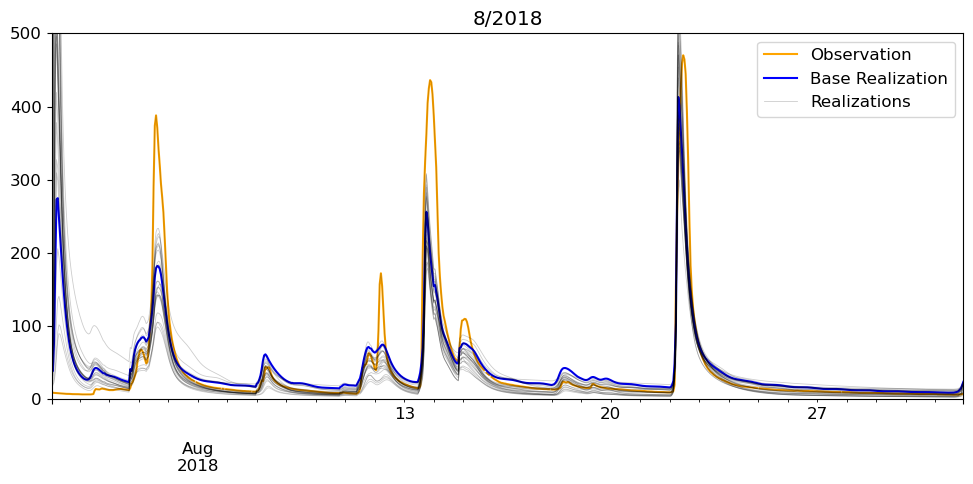

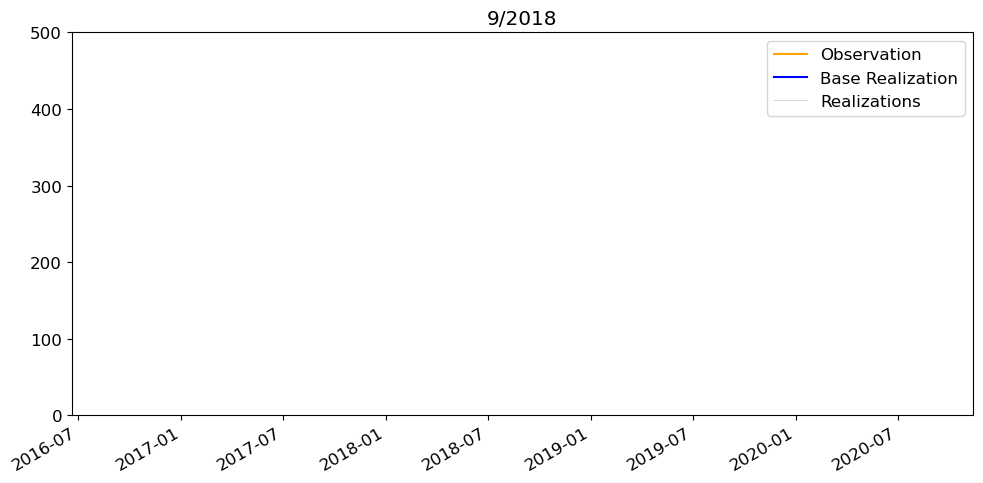

In [24]:
with PdfPages(outdir / 'ens_monthly.pdf') as outpdf:
    for cn, cg in obens.groupby(pd.Grouper(freq="M")):
        print(f'plotting {cn.month:02d}/{cn.year}\r', end='')
        ax = cg.obsval.plot(color='orange', lw=1.5, figsize=(10,5), label='Observation')
        cg.base.plot(ax=ax, lw = 1.5, color='blue', label='Base Realization')
        cg.plot(color='k', lw=.6, alpha=.2, ax=ax, legend=False, label='Realizations')
        plt.legend(labels=['Observation','Base Realization','Realizations'])
        plt.title(f'{cn.month}/{cn.year}')
        plt.tight_layout()
        ax.set_ylim([0,500])
        outpdf.savefig()
        plt.show()
        plt.close('all')

/glade/derecho/scratch/arezoo/tmp/ipykernel_14924/561739485.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.


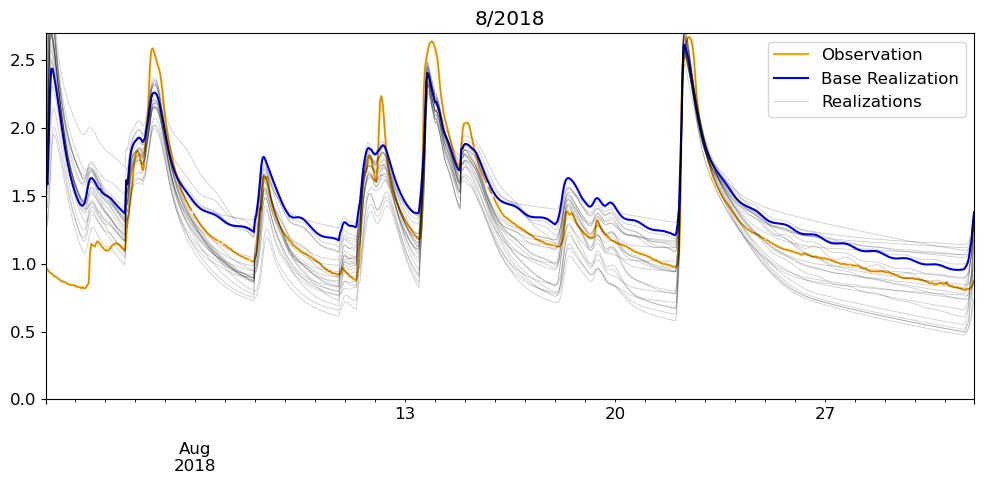

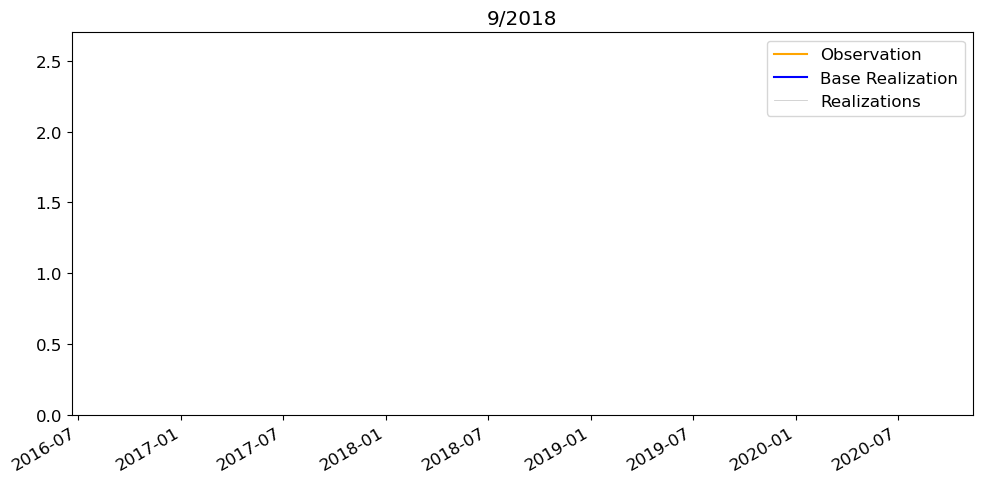

In [25]:
with PdfPages(outdir / 'ens_monthly_log10.pdf') as outpdf:
    for cn, cg in obens.groupby(pd.Grouper(freq="M")):
        print(f'plotting {cn.month:02d}/{cn.year}\r', end='')
        ax = cg.obsval.apply(np.log10).plot(color='orange', lw=1.5, figsize=(10,5), label='Observation')
        cg.base.apply(np.log10).plot(ax=ax, lw = 1.5, color='blue', label='Base Realization')
        cg.apply(np.log10).plot(color='k', lw=.6, alpha=.2, ax=ax, legend=False, label='Realizations')
        plt.legend(labels=['Observation','Base Realization','Realizations'])
        plt.title(f'{cn.month}/{cn.year}')
        plt.tight_layout()
        ax.set_ylim([0,np.log10(500)])
        outpdf.savefig()
        plt.show()
        plt.close('all')


# Check KGE of calibration and validation periods independently

In [26]:
obsval= obens['obsval']
ens_all = obens[[i for i in obens.columns if ('obs' not in i) & ('ens' not in i)]]

In [27]:
val_kge = {}
reals = ens_all.columns
kge_out = [kge_calc(ens_all.loc[(obens.index>='2018-08-02') & (obens.index<'2018-08-10')][i],
                        obsval.loc[(obens.index>='2018-08-02') & (obens.index<'2018-08-10')]) for i in reals]
val_kge = pd.DataFrame({'real':reals,
                           'kge':kge_out})
val_kge.set_index('real', drop=True, inplace=True)

In [28]:
cal_kge = {}
reals = ens_all.columns
kge_out = [kge_calc(ens_all.loc[obens.index>='2018-08-10'][i],
                        obsval.loc[obens.index>='2018-08-10']) for i in reals]
cal_kge = pd.DataFrame({'real':reals,
                           'kge':kge_out})
cal_kge.set_index('real', drop=True, inplace=True)

Text(0.5, 0, 'KGE')

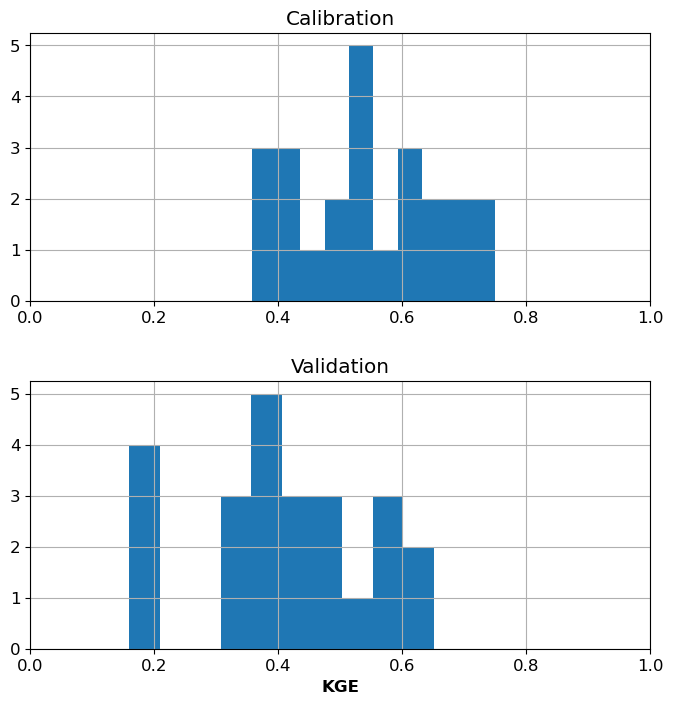

In [29]:
fig, ax = plt.subplots(2,1, figsize=(8,8))

cal_kge.hist(ax=ax[0])
ax[0].set_xlim((0,1))
ax[0].set_title('Calibration')

val_kge.hist( ax=ax[1])
ax[1].set_xlim((0,1))
ax[1].set_title('Validation')

ax[1].set_xlabel('KGE', fontweight ='bold')